# Reproducing the ExtraSensory 2017 Early-Fusion Baseline

Vaizman, Ellis, and Lanckriet, “Recognizing Detailed Human Context In-the-Wild from Smartphones and Smartwatches.”

## tl;dr

The paper reports a 25-label macro balanced accuracy of **0.769** (shown as 0.77); this run obtains **0.768**, 0.001 below. **21/25** per-label scores match the published two-decimal value exactly and **25/25** are within two percentage points. The evaluation population, sensor counts, folds, and every positive-label total reconcile exactly to the paper, so the remaining gaps are model-fit variation rather than a data-split mismatch.

## Context & Methods

This is an analysis-report notebook for a technical reader who wants to inspect the evidence and rerun the baseline. The target is the paper’s first 25 labels and early feature fusion (`EF`). Each label gets an independent class-balanced logistic-regression classifier. Features from the six paper sensor groups are standardized using the outer training fold, missing derived features are set to the training mean (zero after standardization), and `C` is chosen from `{0.001, 0.01, 0.1, 1, 10, 100}` on a stratified one-third validation split by F1. Confusion counts are pooled over the official five user-disjoint folds before balanced accuracy is calculated.

### Key Assumptions

1. The 2017 baseline treated unreported labels as negative. The newer missing-label mask is retained only for optional sensitivity analysis.
2. The paper omits its random seed and software version. This run uses seed `2017` and scikit-learn `1.9.0` with `liblinear`, matching the solver used by the official 2017 tutorial.

Sources: [paper](https://arxiv.org/abs/1609.06354), [official dataset](http://extrasensory.ucsd.edu/), [paper PDF](https://arxiv.org/pdf/1609.06354), and [supplement](http://extrasensory.ucsd.edu/papers/vaizman2017Pervasive_supplementary.pdf).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()
if not (ROOT / 'results').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

## Data

In [2]:
profile = json.loads((RESULTS / 'data_profile.json').read_text())
paper = pd.read_csv(
    ROOT / 'data/reference/paper_balanced_accuracy_5fold_headline.csv'
)
reproduced = pd.read_csv(RESULTS / 'label_metrics.csv').query("model == 'EF'").copy()
fold_metrics = pd.read_csv(RESULTS / 'fold_metrics.csv').query("model == 'EF'").copy()
run_metadata = json.loads((RESULTS / 'run_metadata.json').read_text())

population = pd.DataFrame({
    'check': ['participants', 'labeled minutes', 'six-sensor evaluation minutes', 'six-sensor participants', 'core features', 'duplicate user-timestamps'],
    'observed': [profile['users'], profile['paper_labeled_examples'], profile['core_complete_examples'], profile['core_complete_users'], profile['core_features'], profile['duplicate_user_timestamps']],
    'paper / expected': [60, 308320, 176941, 51, 175, 0],
})
assert (population['observed'] == population['paper / expected']).all()
display(population)

,check,observed,paper / expected
0,participants,60,60
1,labeled minutes,308320,308320
2,six-sensor evaluation minutes,176941,176941
3,six-sensor participants,51,51
4,core features,175,175
5,duplicate user-timestamps,0,0


In [3]:
sensor_coverage = (
    pd.DataFrame(profile['sensor_coverage']).T
    .reset_index(names='sensor')
    [['sensor', 'features', 'available_examples', 'available_users', 'missing_rate']]
)
sensor_coverage['missing_rate'] = sensor_coverage['missing_rate'].map(
    lambda value: f'{value:.1%}'
)
display(sensor_coverage)

,sensor,features,available_examples,available_users,missing_rate
0,Acc,26.0,308306.0,60.0,0.0%
1,Aud,26.0,302177.0,60.0,2.0%
2,Gyro,26.0,291883.0,57.0,5.3%
3,Loc,17.0,273737.0,58.0,11.2%
4,PS,34.0,308320.0,60.0,0.0%
5,WAcc,46.0,210716.0,56.0,31.7%


In [4]:
label_count_check = reproduced.merge(
    paper[['label', 'pretty_label', 'n_examples']],
    on=['label', 'pretty_label'],
    validate='one_to_one',
)
label_count_check['delta'] = (
    label_count_check['test_positive'] - label_count_check['n_examples']
)
assert label_count_check['delta'].eq(0).all()
display(label_count_check[
    ['pretty_label', 'n_examples', 'test_positive', 'delta']
].head(10))
print('All 25 positive-label counts match the paper exactly.')

,pretty_label,n_examples,test_positive,delta
0,Lying down,54359,54359,0
1,Sitting,82904,82904,0
2,Walking,11892,11892,0
3,Running,675,675,0
4,Bicycling,3523,3523,0
5,Sleeping,42920,42920,0
6,Lab work,2898,2898,0
7,In class,2872,2872,0
8,In a meeting,2904,2904,0
9,At main workplace,20382,20382,0


All 25 positive-label counts match the paper exactly.


## Results

In [5]:
comparison = reproduced.merge(
    paper[['label', 'EF']], on='label', validate='one_to_one'
).rename(columns={
    'EF': 'published_ba',
    'balanced_accuracy': 'reproduced_ba',
})
comparison['delta'] = (
    comparison['reproduced_ba'] - comparison['published_ba']
)
summary = pd.DataFrame({
    'metric': ['macro balanced accuracy', 'mean absolute per-label gap', 'two-decimal matches', 'within 0.02'],
    'published / target': [comparison['published_ba'].mean(), 0.0, 25, 25],
    'reproduced': [comparison['reproduced_ba'].mean(), comparison['delta'].abs().mean(), (comparison['reproduced_ba'].round(2) == comparison['published_ba']).sum(), (comparison['delta'].abs() <= 0.02).sum()],
})
display(summary)

,metric,published / target,reproduced
0,macro balanced accuracy,0.7688,0.768271
1,mean absolute per-label gap,0.0000,0.003401
2,two-decimal matches,25.0000,21.000000
3,within 0.02,25.0000,25.000000


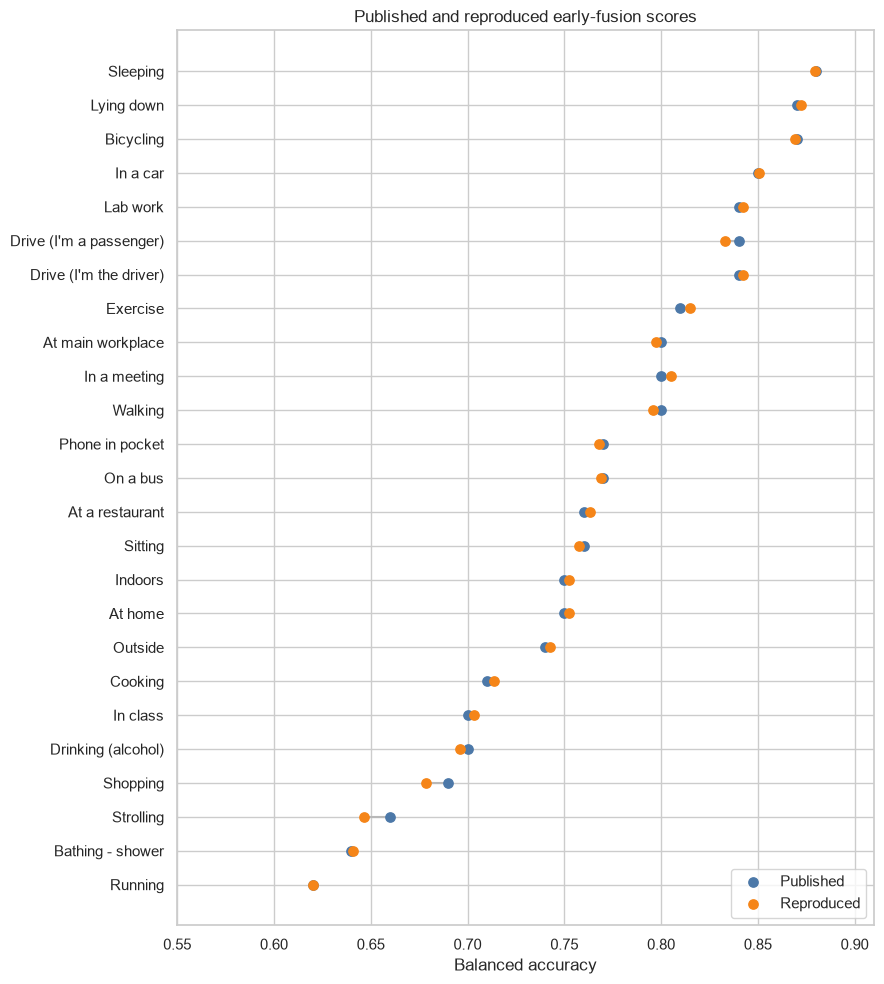

In [6]:
plot_data = comparison.sort_values('published_ba').reset_index(drop=True)
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(9, 10))
ax.hlines(y, plot_data['published_ba'], plot_data['reproduced_ba'], color='#b8b8b8', linewidth=1.5)
ax.scatter(plot_data['published_ba'], y, label='Published', color='#4c78a8', s=45, zorder=3)
ax.scatter(plot_data['reproduced_ba'], y, label='Reproduced', color='#f58518', s=45, zorder=3)
ax.set_yticks(y, plot_data['pretty_label'])
ax.set_xlim(0.55, 0.91)
ax.set_xlabel('Balanced accuracy')
ax.set_title('Published and reproduced early-fusion scores')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIGURES / 'published_vs_reproduced_ef.png', dpi=160)
plt.show()

In [7]:
gap_table = comparison.assign(
    absolute_gap=comparison['delta'].abs()
).sort_values('absolute_gap', ascending=False)[
    ['pretty_label', 'published_ba', 'reproduced_ba', 'delta', 'absolute_gap']
]
display(gap_table.head(10).style.format({
    'published_ba': '{:.3f}', 'reproduced_ba': '{:.3f}', 'delta': '{:+.3f}', 'absolute_gap': '{:.3f}'
}))

,pretty_label,published_ba,reproduced_ba,delta,absolute_gap
22,Strolling,0.660,0.647,-0.013,0.013
21,Shopping,0.690,0.678,-0.012,0.012
15,Drive (I'm a passenger),0.840,0.833,-0.007,0.007
8,In a meeting,0.800,0.805,+0.005,0.005
19,Exercise,0.810,0.815,+0.005,0.005
2,Walking,0.800,0.796,-0.004,0.004
23,Drinking (alcohol),0.700,0.696,-0.004,0.004
20,Cooking,0.710,0.714,+0.004,0.004
7,In class,0.700,0.703,+0.003,0.003
17,At a restaurant,0.760,0.763,+0.003,0.003


In [8]:
selected_c = (
    fold_metrics.groupby(['fold', 'selected_c']).size()
    .unstack(fill_value=0)
    .sort_index(axis=1)
)
display(selected_c)
print('Grid-selected C values across 125 fold-label fits:', fold_metrics['selected_c'].value_counts().sort_index().to_dict())

selected_c,0.001,0.010,0.100,1.000,10.000,100.000
fold,,,,,,
0,0,0,1,12,4,8
1,0,1,3,3,9,9
2,0,0,3,4,7,11
3,0,0,2,4,9,10
4,1,0,1,8,7,8


Grid-selected C values across 125 fold-label fits: {0.001: 1, 0.01: 1, 0.1: 10, 1.0: 31, 10.0: 36, 100.0: 46}


## Takeaways

- The headline result is reproduced directionally and numerically: macro BA is **0.768** versus **0.769** from the published rounded per-label table (difference -0.001).
- **21/25** labels match at the precision published in the supplement; **25/25** differ by no more than 0.02.
- The largest gap is **Strolling** (0.66 published versus 0.647 reproduced). Since the data counts and folds reconcile exactly, the most plausible remaining causes are the unpublished random split seed and numerical/software version differences.
- This run supports the paper’s claim for early sensor fusion. It does not reproduce the late-fusion (`LFA`/`LFL`) columns; the CLI includes the six single-sensor baselines, while a faithful learned late-fusion stack would require an additional choice not fully specified in the paper (how meta-model training probabilities were generated).

### Re-run

From the repository root:

```bash
uv sync --extra dev
uv run extrasensory-reproduce download
uv run extrasensory-reproduce prepare
uv run extrasensory-reproduce profile
uv run extrasensory-reproduce train --models EF --jobs 4
uv run python scripts/build_notebook.py
uv run jupyter nbconvert --execute --to notebook --inplace notebooks/01_paper_reproduction.ipynb
```

Recorded run: Python `3.12.12`, NumPy `2.5.1`, pandas `2.3.3`, scikit-learn `1.9.0`.